# Split data and inspect features

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

## Load recording features

In [2]:
PROJECT_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / "data" / "capslpdb" / "recordings.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")

FEATURE_PATH = PROJECT_ROOT / "outputs" / "preprocessing" / "features_recordings.csv"
SPLIT_DIR = PROJECT_ROOT / "outputs" / "splits"
RANDOM_SEED = 42

signals = ["eeg_delta_power", "eeg_theta_power", "eeg_alpha_power", "eeg_beta_power", "eog_sd_uv", "emg_rms_uv"]
features = [f"{signal}_{statistic}" for signal in signals for statistic in ("median", "p90")]
rem_features = [f"{signal}_rem_{statistic}" for signal in signals for statistic in ("median", "p90")]
ratio_features = ["emg_rem_nrem_ratio_median", "emg_rem_nrem_ratio_p90"]
activity_features = ["emg_rem_active_fraction", "emg_rem_tonic_fraction"]

if not FEATURE_PATH.is_file():
    raise FileNotFoundError("Run notebook 02 to create features_recordings.csv.")
recordings = pd.read_csv(FEATURE_PATH)
columns = ["record_id", "class_name", *features, "rem_windows", *rem_features, "nrem_windows", *ratio_features, *activity_features]
if not set(columns).issubset(recordings.columns):
    raise ValueError("The recording feature table is missing required columns. Run notebook 02 again.")
recordings = recordings[columns].sort_values("record_id").reset_index(drop=True)
if recordings["record_id"].isna().any() or recordings["record_id"].duplicated().any():
    raise ValueError("Each recording needs a unique identifier.")
if set(recordings["class_name"]) != {"healthy", "other", "rbd"}:
    raise ValueError("The feature table must contain healthy, other and rbd recordings.")
if not np.isfinite(recordings[features].to_numpy(dtype=float)).all():
    raise ValueError("The feature table contains missing or non-finite values.")
rem_values = recordings[rem_features + ratio_features + activity_features].to_numpy(dtype=float)
if np.isinf(rem_values).any():
    raise ValueError("The REM features contain infinite values.")
missing_rem = np.isnan(rem_values).any(axis=1)
if missing_rem.any():
    print(f"{missing_rem.sum()} recordings have too few REM or NREM windows for REM features:")
    display(recordings.loc[missing_rem, ["record_id", "class_name", "rem_windows", "nrem_windows"]].reset_index(drop=True))

## Split the recordings

Split each class into approximately 60% training, 10% validation and 30% test data.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)
recordings["split"] = "train"

for class_name, group in recordings.groupby("class_name", sort=True):
    if len(group) < 3:
        raise ValueError(f"At least three recordings are needed for {class_name}.")
    indices = rng.permutation(group.index.to_numpy())
    test_count = max(1, round(len(group) * 0.30))
    validation_count = max(1, round(len(group) * 0.10))
    recordings.loc[indices[:test_count], "split"] = "test"
    recordings.loc[indices[test_count:test_count + validation_count], "split"] = "validation"

splits = {name: recordings.loc[recordings["split"].eq(name), columns].reset_index(drop=True)
          for name in ("train", "validation", "test")}
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
for name, table in splits.items():
    table.to_csv(SPLIT_DIR / f"{name}.csv", index=False)

counts = pd.crosstab(recordings["class_name"], recordings["split"])
display(counts.reindex(columns=["train", "validation", "test"]))

split,train,validation,test
class_name,,,
healthy,9,2,4
other,41,7,21
rbd,13,2,7


## Inspect the training features

Compare the percentage of training recordings in each feature range.

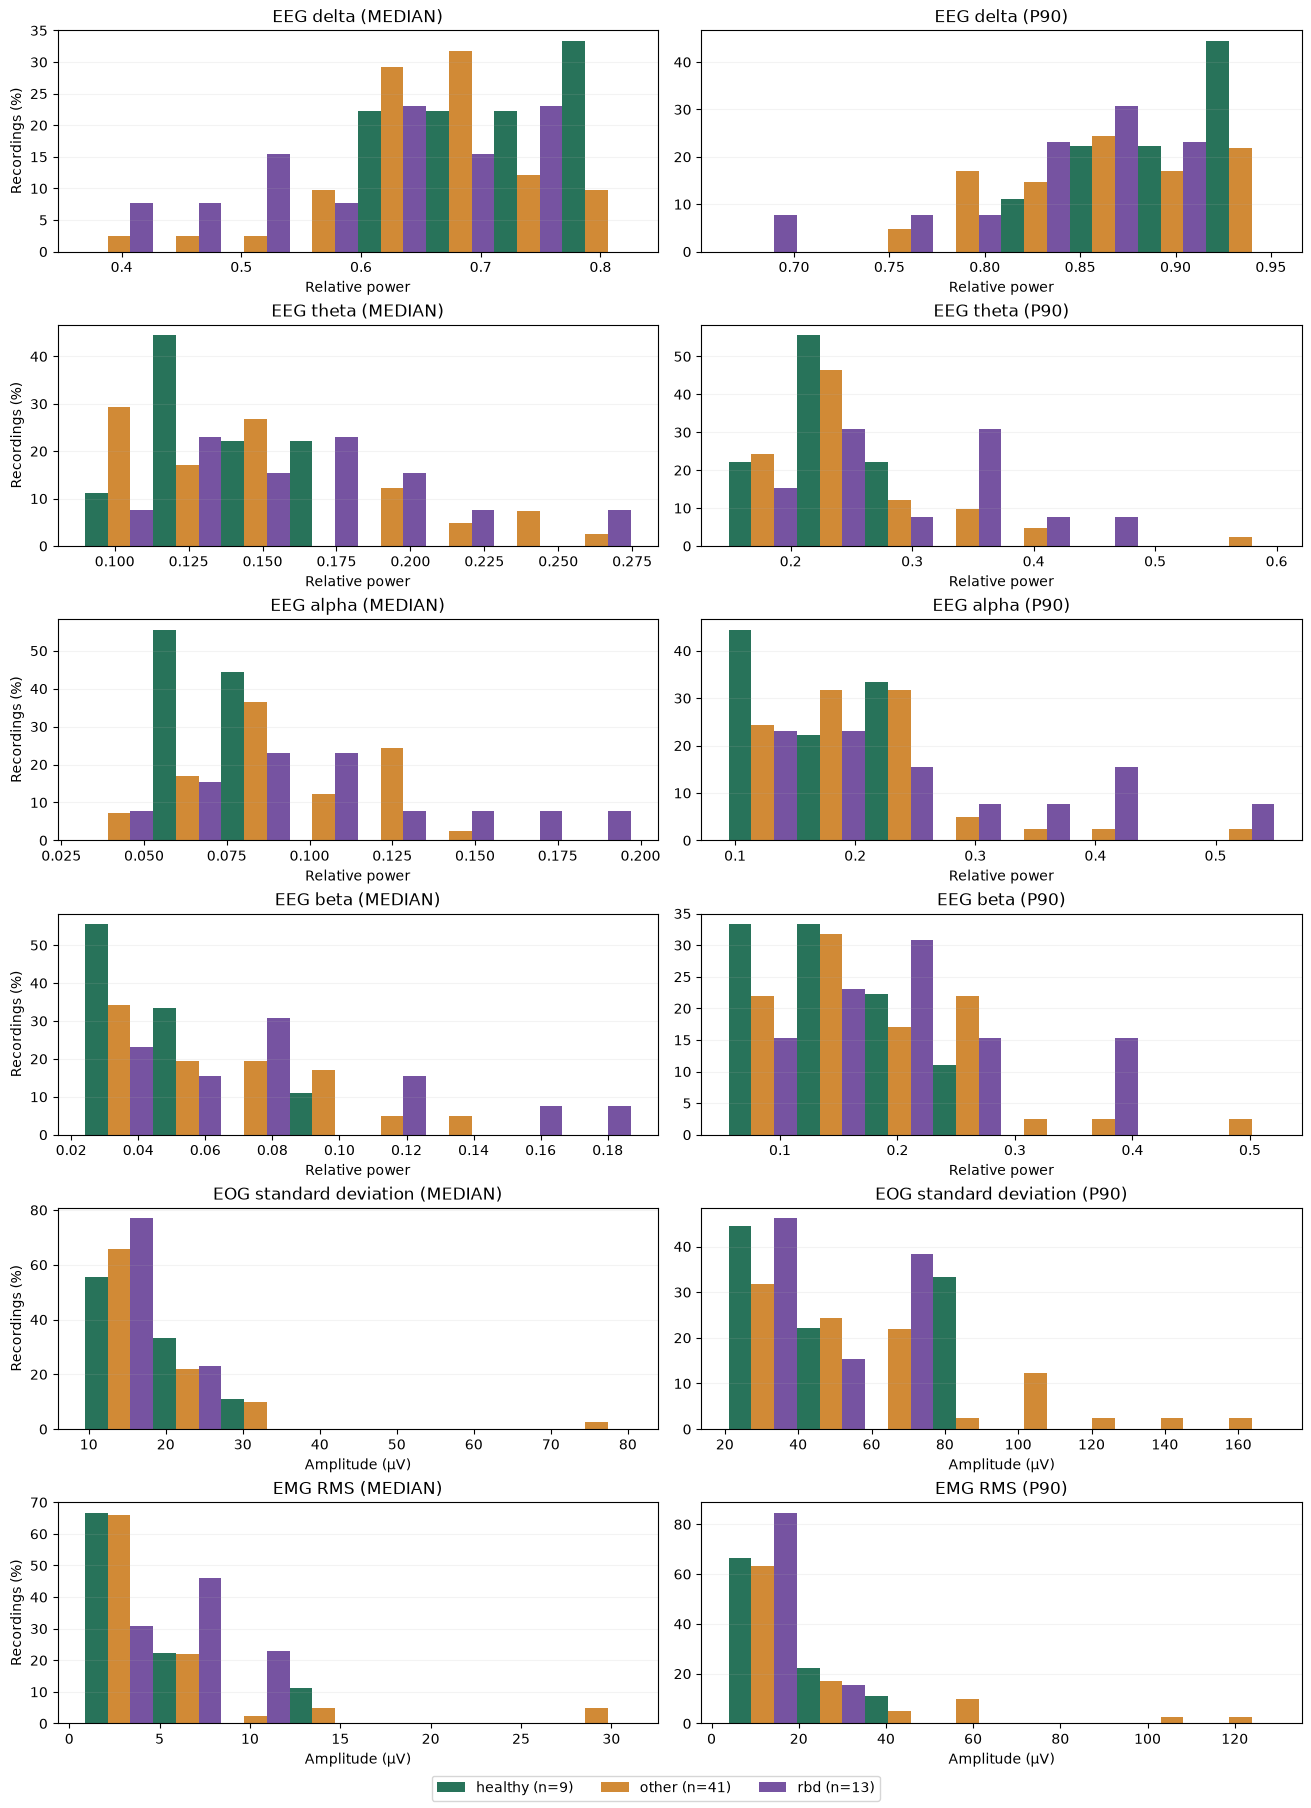

In [4]:
colors = {"healthy": "#28735a", "other": "#d18a36", "rbd": "#7653a1"}
titles = ["EEG delta", "EEG theta", "EEG alpha", "EEG beta", "EOG standard deviation", "EMG RMS"]
training = splits["train"]

fig, axes = plt.subplots(len(signals), 2, figsize=(13, 18), layout="constrained")
for row, (signal, title) in enumerate(zip(signals, titles)):
    for column, statistic in enumerate(("median", "p90")):
        feature = f"{signal}_{statistic}"
        ax = axes[row, column]
        bins = np.histogram_bin_edges(training[feature], bins=8)
        centers = (bins[:-1] + bins[1:]) / 2
        width = (bins[1] - bins[0]) / len(colors)
        for offset, (class_name, color) in enumerate(colors.items()):
            values = training.loc[training["class_name"].eq(class_name), feature]
            counts, _ = np.histogram(values, bins=bins)
            ax.bar(centers + (offset - 1) * width, counts / len(values) * 100, width=width, color=color, label=f"{class_name} (n={len(values)})")
        ax.set_title(f"{title} ({statistic.upper()})")
        ax.set_xlabel("Relative power" if signal.startswith("eeg_") else "Amplitude (µV)")
        if column == 0:
            ax.set_ylabel("Recordings (%)")
        ax.grid(axis="y", alpha=0.15)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
plt.show()